#Проєкт: Прогнозування цін на житло


Мета: навчити модель передбачати медіанну вартість будинку (регресія) на класичному датасеті California Housing (вбудований у sklearn).

>завантаження, EDA, preprocessing, моделі, оцінка, тюнінг, збереження, простий Streamlit UI

##1. Імпорт бібліотек та завантаження датасету

`numpy (np)` – робота з масивами чисел (швидка математика)

`pandas (pd)` – зручно працювати з таблицями (аналог Excel у Python)

`matplotlib.pyplot (plt)` – побудова графіків

`sklearn.datasets` – тут лежить набір даних California Housing

---

`fetch_california_housing()` повертає словник із даними:
- `data` → числові значення ознак (X)
- `target` → те, що ми прогнозуємо (y, ціна житла)
- `feature_names` → список назв ознак (стовпців)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Згадуємо класичне навчання
### Досліджуємо температуру по дням

In [ ]:
data = {
    "Days": [1, 2, 3, 4, 5],
    # "t": [25, 28, 23, 20, 18]
    "t": [25, 28, 23, 30, 18]
}

df = pd.DataFrame(data)
display(df)
print(df)

,Days,t
0,1,25
1,2,28
2,3,23
3,4,30
4,5,18


   Days   t
0     1  25
1     2  28
2     3  23
3     4  30
4     5  18


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Days    5 non-null      int64
 1   t       5 non-null      int64
dtypes: int64(2)
memory usage: 212.0 bytes


In [ ]:
df.describe()

,Days,t
count,5.000000,5.000000
mean,3.000000,24.800000
std,1.581139,4.658326
min,1.000000,18.000000
25%,2.000000,23.000000
50%,3.000000,25.000000
75%,4.000000,28.000000
max,5.000000,30.000000


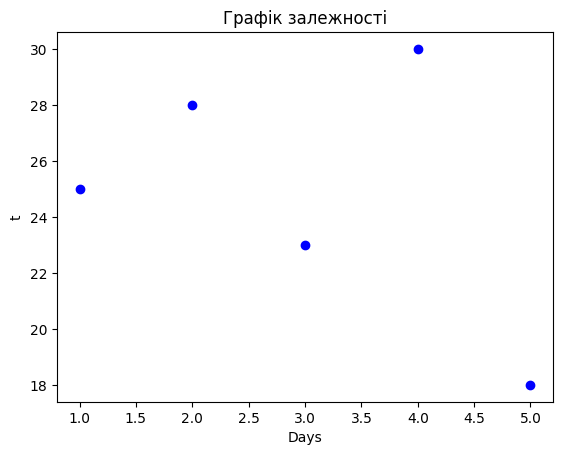

In [ ]:
# plt.plot(X, y)
plt.scatter(df[['Days']], df['t'], color="blue")
plt.title('Графік залежності')
plt.xlabel('Days')
plt.ylabel('t')
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression

X = df[['Days']]
y = df['t']

model = LinearRegression()
model.fit(X, y)

# W
print("W: ", model.coef_)
# b
print("b: ", model.intercept_)

W:  [-1.2]
b:  28.4


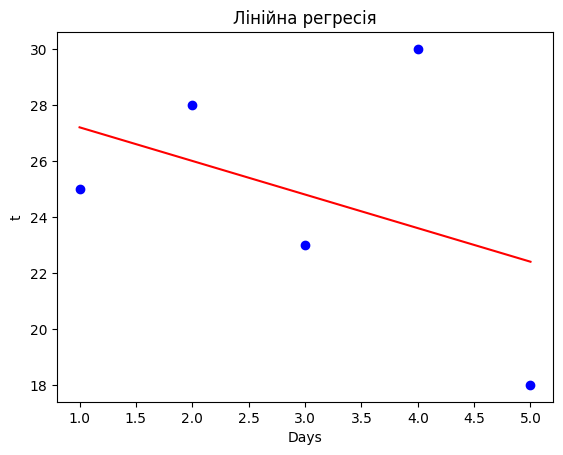

In [ ]:
y_pred = model.predict(X)

plt.scatter(X, y, color="blue")
plt.plot(X, y_pred, color="red")
plt.title('Лінійна регресія')
plt.xlabel('Days')
plt.ylabel('t')
plt.show()

In [ ]:
new_value = [[7]]
predict_t = model.predict(new_value)
print(predict_t)

[20.]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## Проєкт "Оцінка житла"

In [ ]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Основні стовпчики (фічі):

- MedInc – середній дохід у районі (у десятках тисяч $)
- HouseAge – середній вік будинків у районі
- AveRooms – середня кількість кімнат
- AveBedrms – середня кількість спалень
- Population – кількість людей у районі
- AveOccup – середня кількість мешканців на будинок
- Latitude – широта (географія)
- Longitude – довгота (географія)

Ціль:

- MedHouseVal – середня ціна будинку (в сотнях тисяч $)

##2. Дослідження даних (EDA)

Дивимося розподіли, пропуски та кореляції між ознаками й таргетом. Це допоможе подумати про інженерію ознак.

`info()` показує типи даних та чи є пропуски.

`describe()` дає статистику: середнє, мінімум, максимум, квартилі.

-----------------

* feature - фіча - ознака - `X` (к-ть кімнат, дохід, вік будинку ...)
* target - таргет - ціль - `y` (ціна)
* fit / training - навчання (підбирання параметрів на прикладах) - `model.fit(X_train, y_train)`
* predict - прогноз - відповідь моделі на нових даних - `model.predict(X_test)`
* train set - навчальна вибірка (80%) - `X_train, y_train`
* test set - тестова вибірка (20%) - `X_test, y_test`

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [ ]:
df.isna().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [ ]:
f"{0.1254456789:.2f}"

'0.13'

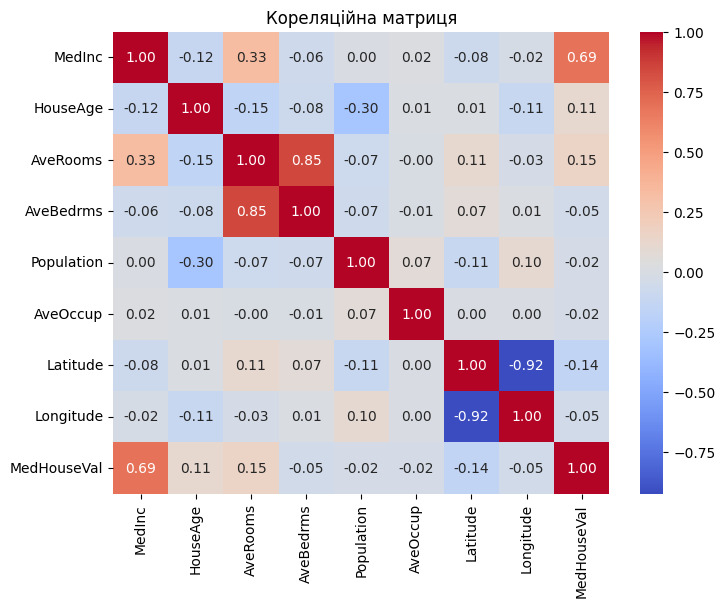

In [ ]:
plt.figure(figsize=(8,6))
corr = df.corr()
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
  )
plt.title("Кореляційна матриця")
plt.show()

In [ ]:
X = df[['MedInc']]
y = df['MedHouseVal']

In [ ]:
type(y)

pandas.core.series.Series

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((16512, 1), (4128, 1))

In [ ]:
y_test

,MedHouseVal
20046,0.47700
3024,0.45800
15663,5.00001
20484,2.18600
9814,2.78000
...,...
15362,2.63300
16623,2.66800
18086,5.00001
2144,0.72300


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(model.coef_, model.intercept_)

[0.41933849] 0.4445972916907879


In [ ]:
type(X_test)

pandas.core.frame.DataFrame

In [ ]:
pd.DataFrame({
    'MedInc': X_test['MedInc'],
    'MedHouseVal_predict': y_pred,
    'MedHouseVal': y_test,
    # '%':
})

,MedInc,MedHouseVal_predict,MedHouseVal
20046,1.6812,1.149589,0.47700
3024,2.5313,1.506069,0.45800
15663,3.4801,1.903937,5.00001
20484,5.7376,2.850594,2.18600
9814,3.7250,2.006633,2.78000
...,...,...,...
15362,4.6050,2.375651,2.63300
16623,2.7266,1.587966,2.66800
18086,9.2298,4.315008,5.00001
2144,2.7850,1.612455,0.72300


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
# print("RMSE:", mse ** 0.5, "(в сотнях тисяч $)")
print(f"RMSE: {rmse} (в сотнях тисяч $) ~ {rmse * 100:.0f}K $")

print("Коефіцієнт детермінації:", r2)
print(f"Коефіцієнт детермінації: {r2} -> наша модель пояснює ~{r2 * 100:.0f}%")

MSE: 0.7091157771765549
RMSE: 0.8420901241414455 (в сотнях тисяч $) ~ 84K $
Коефіцієнт детермінації: 0.45885918903846656
Коефіцієнт детермінації: 0.45885918903846656 -> наша модель пояснює ~46%


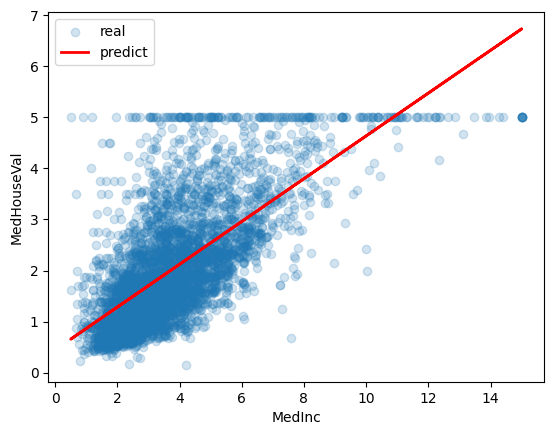

In [ ]:
plt.scatter(X_test, y_test, alpha=0.2, label="real")
plt.plot(X_test, y_pred, color="red", linewidth=2, label="predict")
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")
plt.legend()
plt.show()

## Багатовимірна лінійна регресія

In [ ]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [ ]:
X = df[['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude']]
y = df['MedHouseVal']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(model.coef_, model.intercept_)

[ 4.48674910e-01  9.72425752e-03 -1.23323343e-01  7.83144907e-01
 -2.02962058e-06 -3.52631849e-03 -4.19792487e-01 -4.33708065e-01] -37.02327770606409


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
# print("RMSE:", mse ** 0.5, "(в сотнях тисяч $)")
print(f"RMSE: {rmse} (в сотнях тисяч $) ~ {rmse * 100:.0f}K $")

print("Коефіцієнт детермінації:", r2)
print(f"Коефіцієнт детермінації: {r2} -> наша модель пояснює ~{r2 * 100:.0f}%")

MSE: 0.5558915986952444
RMSE: 0.7455813830127764 (в сотнях тисяч $) ~ 75K $
Коефіцієнт детермінації: 0.5757877060324508
Коефіцієнт детермінації: 0.5757877060324508 -> наша модель пояснює ~58%


In [ ]:
pd.Series(model.coef_, index=X.columns)

,0
MedInc,0.448675
HouseAge,0.009724
AveRooms,-0.123323
AveBedrms,0.783145
Population,-0.000002
AveOccup,-0.003526
Latitude,-0.419792
Longitude,-0.433708
